In [1]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib as mpl
from neuron import h
import multiprocessing as mp
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter1d
import yaml
import seaborn as sns
import itertools
from matplotlib.ticker import ScalarFormatter

--No graphics will be displayed.


In [2]:
sgc_pop = populations.SGC()
pyr_pop = populations.Pyramidal()
ds_pop = populations.DStellate()
vert_pop = populations.Tuberculoventral()

sgc_cfs = sgc_pop._get_cf_array(species='mouse')
pyr_cfs = pyr_pop._get_cf_array(species='mouse')
ds_cfs = ds_pop._get_cf_array(species='mouse')
vert_cfs = vert_pop._get_cf_array(species='mouse')

In [3]:
stimpar = {"dur": 0.26,
           "pip": 0.1,
           "start": [0.125],
           "baseline": [25, 125],
           "response": [125, 225]}

In [4]:
response_weights = {'III': {'sp': 0.00036,
                            'vp': 0.0014,
                            'dp': 0.002228},
                    'IV': {'sp': 0.00028,
                           'vp': 0.0038,
                           'dp': 0.002228}}

In [5]:
hearing_colors = {'normal': '#A31621',
                  'loss': '#A5B452',
                  'loss_hp': '#44CCFF',
                  'loss_erev': '#F37748'}

# Type III

In [6]:
level = 60
nreps = 5
pyr_type = 'III'
loss_limit = 15000
cohc = 0.8
cihc = 0.8
sgn_loss = 50

In [7]:
top_dir = '/data/scrook/dcnmodel_scratch/output/PCA-III-tuning_curve'

In [11]:
for input_freq in input_freqs:

    print(np.round(input_freq*1e-3,1))

0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9
2.0
2.1
2.2
2.3
2.4
2.5
2.6
2.7
2.8
2.9
3.0
3.1
3.2
3.3
3.4
3.5
3.6
3.7
3.8
3.9
4.0
4.1
4.2
4.3
4.4
4.5
4.6
4.7
4.8
4.9
5.0
5.1
5.2
5.3
5.4
5.5
5.6
5.7
5.8
5.9
6.0
6.1
6.2
6.3
6.4
6.5
6.6
6.7
6.8
6.9
7.0
7.1
7.2
7.3
7.4
7.5
7.6
7.7
7.8
7.9
8.0
8.1
8.2
8.3
8.4
8.5
8.6
8.7
8.8
8.9
9.0
9.1
9.2
9.3
9.4
9.5
9.6
9.7
9.8
9.9
10.0
10.1
10.2
10.3
10.4
10.5
10.6
10.7
10.8
10.9
11.0
11.1
11.2
11.3
11.4
11.5
11.6
11.7
11.8
11.9
12.0
12.1
12.2
12.3
12.4
12.5
12.6
12.7
12.8
12.9
13.0
13.1
13.2
13.3
13.4
13.5
13.6
13.7
13.8
13.9
14.0
14.1
14.2
14.3
14.4
14.5
14.6
14.7
14.8
14.9
15.0
15.1
15.2
15.3
15.4
15.5
15.6
15.7
15.8
15.9
16.0
16.1
16.2
16.3
16.4
16.5
16.6
16.7
16.8
16.9
17.0
17.1
17.2
17.3
17.4
17.5
17.6
17.7
17.8
17.9
18.0
18.1
18.2
18.3
18.4
18.5
18.6
18.7
18.8
18.9
19.0
19.1
19.2
19.3
19.4
19.5
19.6
19.7
19.8
19.9
20.0
20.1
20.2
20.3
20.4
20.5
20.6
20.7
20.8
20.9
21.0
21.1
21.2
21.3
21.4
21.5
21.6
21.7
21.8
21.9
22.0

In [67]:
pyr_tc_data = {'characteristic_freq': [],
               'id': [],
               'hearing': [],
               'tuning_curve': [],
               'spont_rates': []}

cfs = [10, 15.3, 20]  # kHz
hearings = ['normal', 'loss', 'loss_hp', 'loss_erev']
hfs = [1.0, 1.0, 2.0, 1.0]
  # np.union1d(np.arange(0.1, 50, 0.5)*1e3, np.arange(4, 41, 4)*1e3)
input_freqs_full = np.arange(100, 50000, 100)
input_freqs = input_freqs_full / 1000
erev = -46

for cf in cfs:

    for h_i, hearing in enumerate(hearings):  #, 'loss', 'loss_hp']:

        pyr_tc_data['characteristic_freq'].append(cf)
        pyr_id = np.argmin(np.abs(cf*1e3 - pyr_cfs))
        pyr_tc_data['id'].append(pyr_id)
        pyr_tc_data['hearing'].append(hearing)
        cf_tc = []
        cf_sponts = []

        for if_i, input_freq in enumerate(input_freqs):

            sim_dir = os.path.join(top_dir, f'665cfs-{input_freq}kHz_{level}dB-{nreps}nreps')
            if 'loss' in hearing:
                if 'erev' in hearing:
                    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN-Erev{erev}')
                else:
                    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            else:
                hearing_dir = os.path.join(sim_dir, 'NORMAL')

        # print(hearing, hearing_dir)
            # hearing_dir = os.path.join(sim_dir, 'NORMAL') if 'normal' in hearing else os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hfs[h_i]}")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            # print(if_i, input_freqs_full[if_i])
            pyr_idx = np.where(data_frs['evoked_rates']['pyramidal'][0][(input_freqs_full[if_i], level)] == pyr_id)[0][0]
            freq_rate = data_frs['evoked_rates']['pyramidal'][1][(input_freqs_full[if_i], level)][pyr_idx]
            spont_rate = data_frs['spont_rates']['pyramidal'][1][(input_freqs_full[if_i], level)][pyr_idx]
            cf_tc.append(freq_rate)
            cf_sponts.append(spont_rate)
        
        pyr_tc_data['tuning_curve'].append(np.array(cf_tc))
        pyr_tc_data['spont_rates'].append(np.array(cf_sponts))

pyr_tc_df = pd.DataFrame.from_dict(pyr_tc_data)

In [68]:
pyr_tc_df

,characteristic_freq,id,hearing,tuning_curve,spont_rates
0,10.0,1852,normal,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112..."
1,10.0,1852,loss,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112..."
2,10.0,1852,loss_hp,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112..."
3,10.0,1852,loss_erev,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112..."
4,15.3,2115,normal,"[138.0, 138.0, 136.0, 138.0, 138.0, 138.0, 140...","[156.0, 156.0, 156.0, 156.0, 156.0, 156.0, 156..."
5,15.3,2115,loss,"[86.0, 78.0, 90.0, 94.0, 94.0, 96.0, 80.0, 90....","[102.0, 92.0, 108.0, 104.0, 102.0, 98.0, 100.0..."
6,15.3,2115,loss_hp,"[216.0, 226.0, 222.0, 224.0, 230.0, 200.0, 232...","[238.0, 240.0, 232.0, 232.0, 236.0, 216.0, 240..."
7,15.3,2115,loss_erev,"[202.0, 200.0, 194.0, 192.0, 194.0, 200.0, 200...","[212.0, 210.0, 204.0, 206.0, 208.0, 206.0, 208..."
8,20.0,2281,normal,"[50.0, 52.0, 52.0, 50.0, 52.0, 52.0, 52.0, 52....","[64.0, 64.0, 64.0, 64.0, 64.0, 64.0, 64.0, 64...."
9,20.0,2281,loss,"[2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 2.0, 2.0, ...","[2.0, 6.0, 2.0, 4.0, 4.0, 0.0, 2.0, 8.0, 6.0, ..."


In [ ]:
pyr_tc_df.tuning_curve[0].shape

(499,)

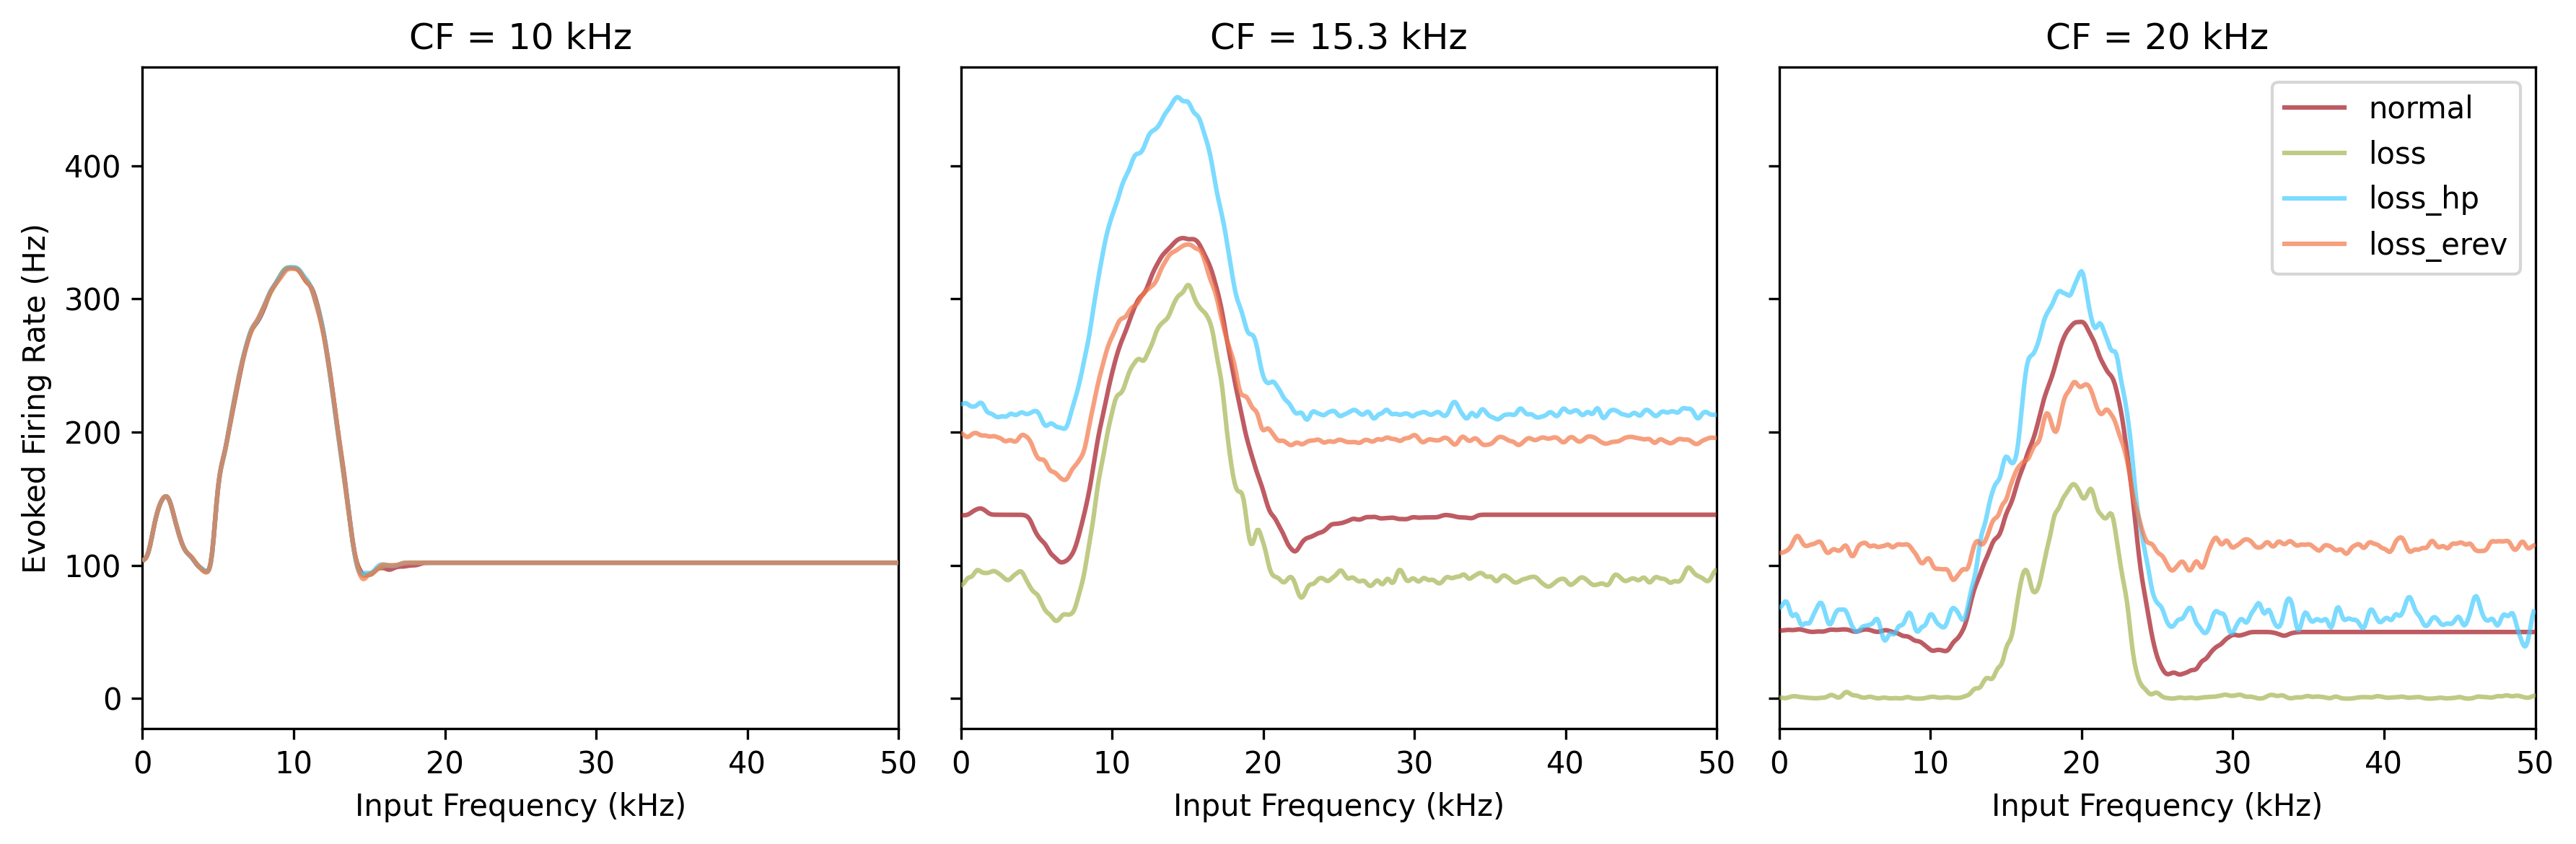

In [205]:
octave = 1
octave_xlim = False

freq_xlim = False
smooth = True

peak_freqs = []
peak_rates = []
fwhhs = []

spont_rate = np.average(pyr_tc_df.spont_rates[0])

fig, axs = plt.subplots(1, len(cfs), figsize=(4*len(cfs), 4), sharey=True, sharex=False)
axs = axs.ravel()

for cf_i, cf in enumerate(cfs):

    cf_df = pyr_tc_df[pyr_tc_df.characteristic_freq == cf]

    for row_i, row in cf_df.iterrows():

        tuning_curve = row.tuning_curve #- np.min(row.tuning_curve)  #- row.spont_rates[0]
        if smooth:
            # tuning_curve = savgol_filter(tuning_curve, window_length=11, polyorder=3)
            tuning_curve = gaussian_filter1d(tuning_curve, sigma=2)
        
        axs[cf_i].plot(input_freqs_full - cf*0e3, tuning_curve, label=row.hearing, color=hearing_colors[row.hearing], alpha=0.7, zorder=12)
        peak_idx = np.argmax(tuning_curve)
        peak_rate = tuning_curve[peak_idx]
        peak_freq = input_freqs_full[peak_idx]

        n_edge = 5
        baseline = row.spont_rates[peak_idx]
        half_height = baseline + 0.5 * (peak_rate - baseline)

        half_peak = peak_rate / 2

        left = np.nan
        for i in range(peak_idx-1,-1,-1):
            if tuning_curve[i] < half_height <= tuning_curve[i+1]:
                left = np.interp(half_height, [tuning_curve[i], tuning_curve[i+1]], [input_freqs_full[i], input_freqs_full[i+1]])
                break

        right = np.nan
        for i in range(peak_idx,len(tuning_curve)-1):
            if tuning_curve[i] >= half_height > tuning_curve[i+1]:
                right = np.interp(half_height, [tuning_curve[i], tuning_curve[i+1]], [input_freqs_full[i], input_freqs_full[i+1]])
                break

        # axs[cf_i].hlines(half_height, left-cf*0e3, right-cf*0e3, color=hearing_colors[row.hearing], linestyle='--', lw=2, alpha=0.8, zorder=1)

        # axs[cf_i].axvline(peak_freq - cf*0e3, color=hearing_colors[row.hearing], alpha=0.7, zorder=1)

        peak_freqs.append(peak_freq)
        peak_rates.append(peak_rate)
        fwhhs.append(right-left)

        # print(f'{cf} - {row.hearing} - peak at {input_freqs[peak_idx]} kHz')
        # print(f'{cf} - {row.hearing} - FWHH = {np.round((right - left)*1e-3,2)} kHz')

    axs[cf_i].set_title(f'CF = {cf} kHz')
    if octave_xlim:
        xlims = [cf*1e3 * 2**-octave, cf*1e3 * 2**octave]
        print(cf, xlims)
        axs[cf_i].set_xlim(xlims)

axs[0].set_ylabel('Evoked Firing Rate (Hz)')
# axs[0].set_xlim([-20000, 20000])

for ax in axs:
    # ax.set_xlabel('Distance from BF (kHz)')
    if octave_xlim:
        ax.set_xlabel('Distance from BF (octaves)')
    elif freq_xlim:
        f_dist = 10
        ax.set_xlabel('Input Frequency from BF (kHz)')
        ax.set_xlim([-f_dist*1e3, f_dist*1e3])
        ax.set_xticks([-f_dist*1e3, 0, f_dist*1e3])
        ax.set_xticklabels([-f_dist, 0, f_dist])
    else:
        ax.set_xlabel('Input Frequency (kHz)')
        ax.set_xticks([0, 10000, 20000, 30000, 40000, 50000])
        ax.set_xticklabels([0, 10, 20, 30, 40, 50])
        ax.set_xlim([0,50000])

axs[-1].legend(loc='upper right')
fig.set_dpi(300)
fig.tight_layout()

fig.savefig('PCA-tuning_curves-if.png', bbox_inches='tight', dpi=300)
fig.savefig('PCA-tuning_curves-if.pdf', bbox_inches='tight', dpi=300)


In [225]:
edge_tc_hp = pyr_tc_df[(pyr_tc_df.characteristic_freq == 15.3) & (pyr_tc_df.hearing == 'loss_hp')].tuning_curve.iloc[0]
edge_tc_norm = pyr_tc_df[(pyr_tc_df.characteristic_freq == 15.3) & (pyr_tc_df.hearing == 'normal')].tuning_curve.iloc[0] 
edge_tc_erev = pyr_tc_df[(pyr_tc_df.characteristic_freq == 15.3) & (pyr_tc_df.hearing == 'loss_erev')].tuning_curve.iloc[0]

In [223]:
edge_diff = edge_tc_hp - edge_tc_norm

In [221]:
area_normal = np.trapezoid(edge_tc_norm, input_freqs_full)
area_hp = np.trapezoid(edge_tc_hp, input_freqs_full)

percent = 100 * (area_hp - area_normal) / area_normal

In [222]:
percent

np.float64(51.444078076488005)

In [226]:
np.mean(edge_tc_erev), np.min(edge_tc_erev), np.max(edge_tc_erev)

(np.float64(214.12825651302606), np.float64(158.0), np.float64(346.0))

In [227]:
np.min(edge_tc_erev) - np.max(edge_tc_erev), np.min(edge_tc_hp) - np.max(edge_tc_hp), np.min(edge_tc_norm) - np.max(edge_tc_norm)

(np.float64(-188.0), np.float64(-268.0), np.float64(-250.0))

In [206]:
pyr_tc_df['peak_freq'] = peak_freqs
pyr_tc_df['peak_rate'] = peak_rates
pyr_tc_df['fwhh'] = fwhhs

In [207]:
pyr_tc_df

,characteristic_freq,id,hearing,tuning_curve,spont_rates,peak_freq,fwhh,peak_shift,fwhh_shift,peak_rate
0,10.0,1852,normal,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112...",9800,6802.096637,0.000000,0.000000,323.563757
1,10.0,1852,loss,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112...",10000,6830.383758,-0.128380,28.287120,323.435376
2,10.0,1852,loss_hp,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112...",9900,6749.515463,0.127727,-52.581174,323.691484
3,10.0,1852,loss_erev,"[102.0, 104.0, 106.0, 106.0, 110.0, 120.0, 130...","[112.0, 112.0, 112.0, 112.0, 112.0, 112.0, 112...",9900,6835.914642,-0.992099,33.818005,322.571657
4,15.3,2115,normal,"[138.0, 138.0, 136.0, 138.0, 138.0, 138.0, 140...","[156.0, 156.0, 156.0, 156.0, 156.0, 156.0, 156...",14700,7848.550853,0.000000,0.000000,345.623843
5,15.3,2115,loss,"[86.0, 78.0, 90.0, 94.0, 94.0, 96.0, 80.0, 90....","[102.0, 92.0, 108.0, 104.0, 102.0, 98.0, 100.0...",15000,7421.453060,-35.207105,-427.097793,310.416737
6,15.3,2115,loss_hp,"[216.0, 226.0, 222.0, 224.0, 230.0, 200.0, 232...","[238.0, 240.0, 232.0, 232.0, 236.0, 216.0, 240...",14300,8213.861657,105.764738,365.310804,451.388581
7,15.3,2115,loss_erev,"[202.0, 200.0, 194.0, 192.0, 194.0, 200.0, 200...","[212.0, 210.0, 204.0, 206.0, 208.0, 206.0, 208...",15000,7419.432293,-4.809606,-429.118560,340.814237
8,20.0,2281,normal,"[50.0, 52.0, 52.0, 50.0, 52.0, 52.0, 52.0, 52....","[64.0, 64.0, 64.0, 64.0, 64.0, 64.0, 64.0, 64....",20000,7079.313019,0.000000,0.000000,282.760876
9,20.0,2281,loss,"[2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 2.0, 2.0, ...","[2.0, 6.0, 2.0, 4.0, 4.0, 0.0, 2.0, 8.0, 6.0, ...",19500,5901.294358,-121.835392,-1178.018661,160.925484


In [ ]:
normal_peak = {
    10.0: pyr_tc_df[(pyr_tc_df.characteristic_freq == 10) & (pyr_tc_df.hearing == 'normal')].peak_rate.iloc[0],
    15.3: pyr_tc_df[(pyr_tc_df.characteristic_freq == 15.3) & (pyr_tc_df.hearing == 'normal')].peak_rate.iloc[0],
    20.0: pyr_tc_df[(pyr_tc_df.characteristic_freq == 20) & (pyr_tc_df.hearing == 'normal')].peak_rate.iloc[0]
}

normal_fwhh = {
    10.0: pyr_tc_df[(pyr_tc_df.characteristic_freq == 10) & (pyr_tc_df.hearing == 'normal')].fwhh.iloc[0],
    15.3: pyr_tc_df[(pyr_tc_df.characteristic_freq == 15.3) & (pyr_tc_df.hearing == 'normal')].fwhh.iloc[0],
    20.0: pyr_tc_df[(pyr_tc_df.characteristic_freq == 20) & (pyr_tc_df.hearing == 'normal')].fwhh.iloc[0]
}

pyr_tc_df['peak_shift'] = (
    pyr_tc_df['peak_rate']
    - pyr_tc_df['characteristic_freq'].map(normal_peak)
)

pyr_tc_df['fwhh_shift'] = (
    pyr_tc_df['fwhh']
    - pyr_tc_df['characteristic_freq'].map(normal_fwhh)
)

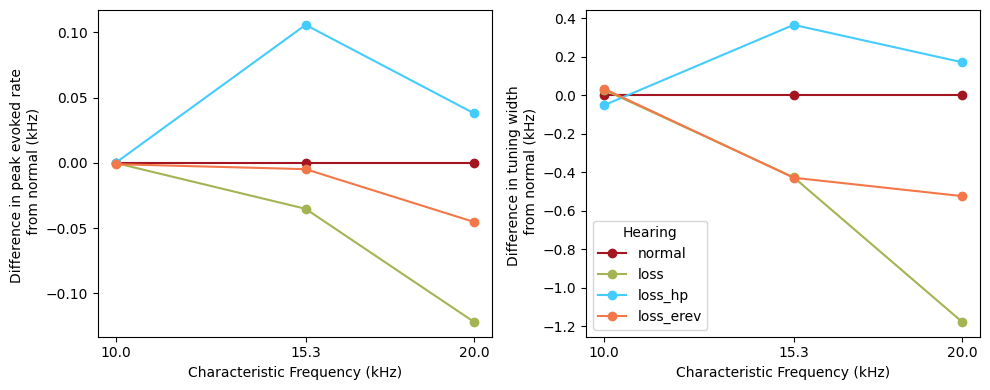

In [210]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

hearing_order = ['normal', 'loss', 'loss_hp', 'loss_erev']

for hearing in hearing_order:

    df = (
        pyr_tc_df[pyr_tc_df.hearing == hearing]
        .sort_values('characteristic_freq')
    )

    axs[0].plot(
        df.characteristic_freq,
        df.peak_shift / 1000,   # Hz -> kHz
        '-o',
        label=hearing,
        color=hearing_colors[hearing]
    )

    axs[1].plot(
        df.characteristic_freq,
        df.fwhh_shift / 1000,   # Hz -> kHz
        '-o',
        label=hearing,
        color=hearing_colors[hearing]
    )

for ax in axs:
    # ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xlabel('Characteristic Frequency (kHz)')
    ax.set_xticks(sorted(pyr_tc_df.characteristic_freq.unique()))

axs[0].set_ylabel('Difference in peak evoked rate \n from normal (kHz)')
axs[1].set_ylabel('Difference in tuning width \n from normal (kHz)')

axs[1].legend(title='Hearing')

fig.tight_layout()
fig.savefig('PCA-tuning_curves_compare.png', bbox_inches='tight', dpi=300)
fig.savefig('PCA-tuning_curves_compare.pdf', bbox_inches='tight', dpi=300)

In [124]:
input_freqs[0], input_freqs[1]

(np.float64(0.1), np.float64(0.2))

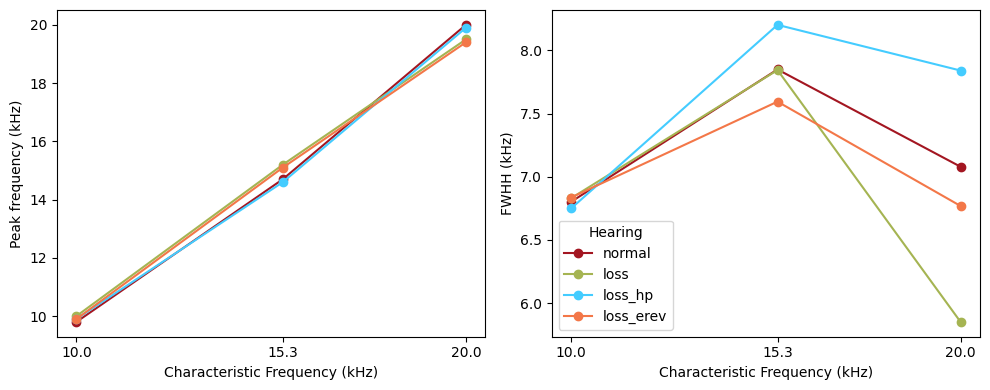

In [119]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

hearing_order = ['normal', 'loss', 'loss_hp', 'loss_erev']

for hearing in hearing_order:

    df = (
        pyr_tc_df[pyr_tc_df.hearing == hearing]
        .sort_values('characteristic_freq')
    )

    axs[0].plot(
        df.characteristic_freq,
        df.peak_freq / 1000,   # Hz -> kHz
        '-o',
        label=hearing,
        color=hearing_colors[hearing]
    )

    axs[1].plot(
        df.characteristic_freq,
        df.fwhh / 1000,   # Hz -> kHz
        '-o',
        label=hearing,
        color=hearing_colors[hearing]
    )

for ax in axs:
    # ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xlabel('Characteristic Frequency (kHz)')
    ax.set_xticks(sorted(pyr_tc_df.characteristic_freq.unique()))

axs[0].set_ylabel('Peak frequency (kHz)')
axs[1].set_ylabel('FWHH (kHz)')

axs[1].legend(title='Hearing')

fig.tight_layout()

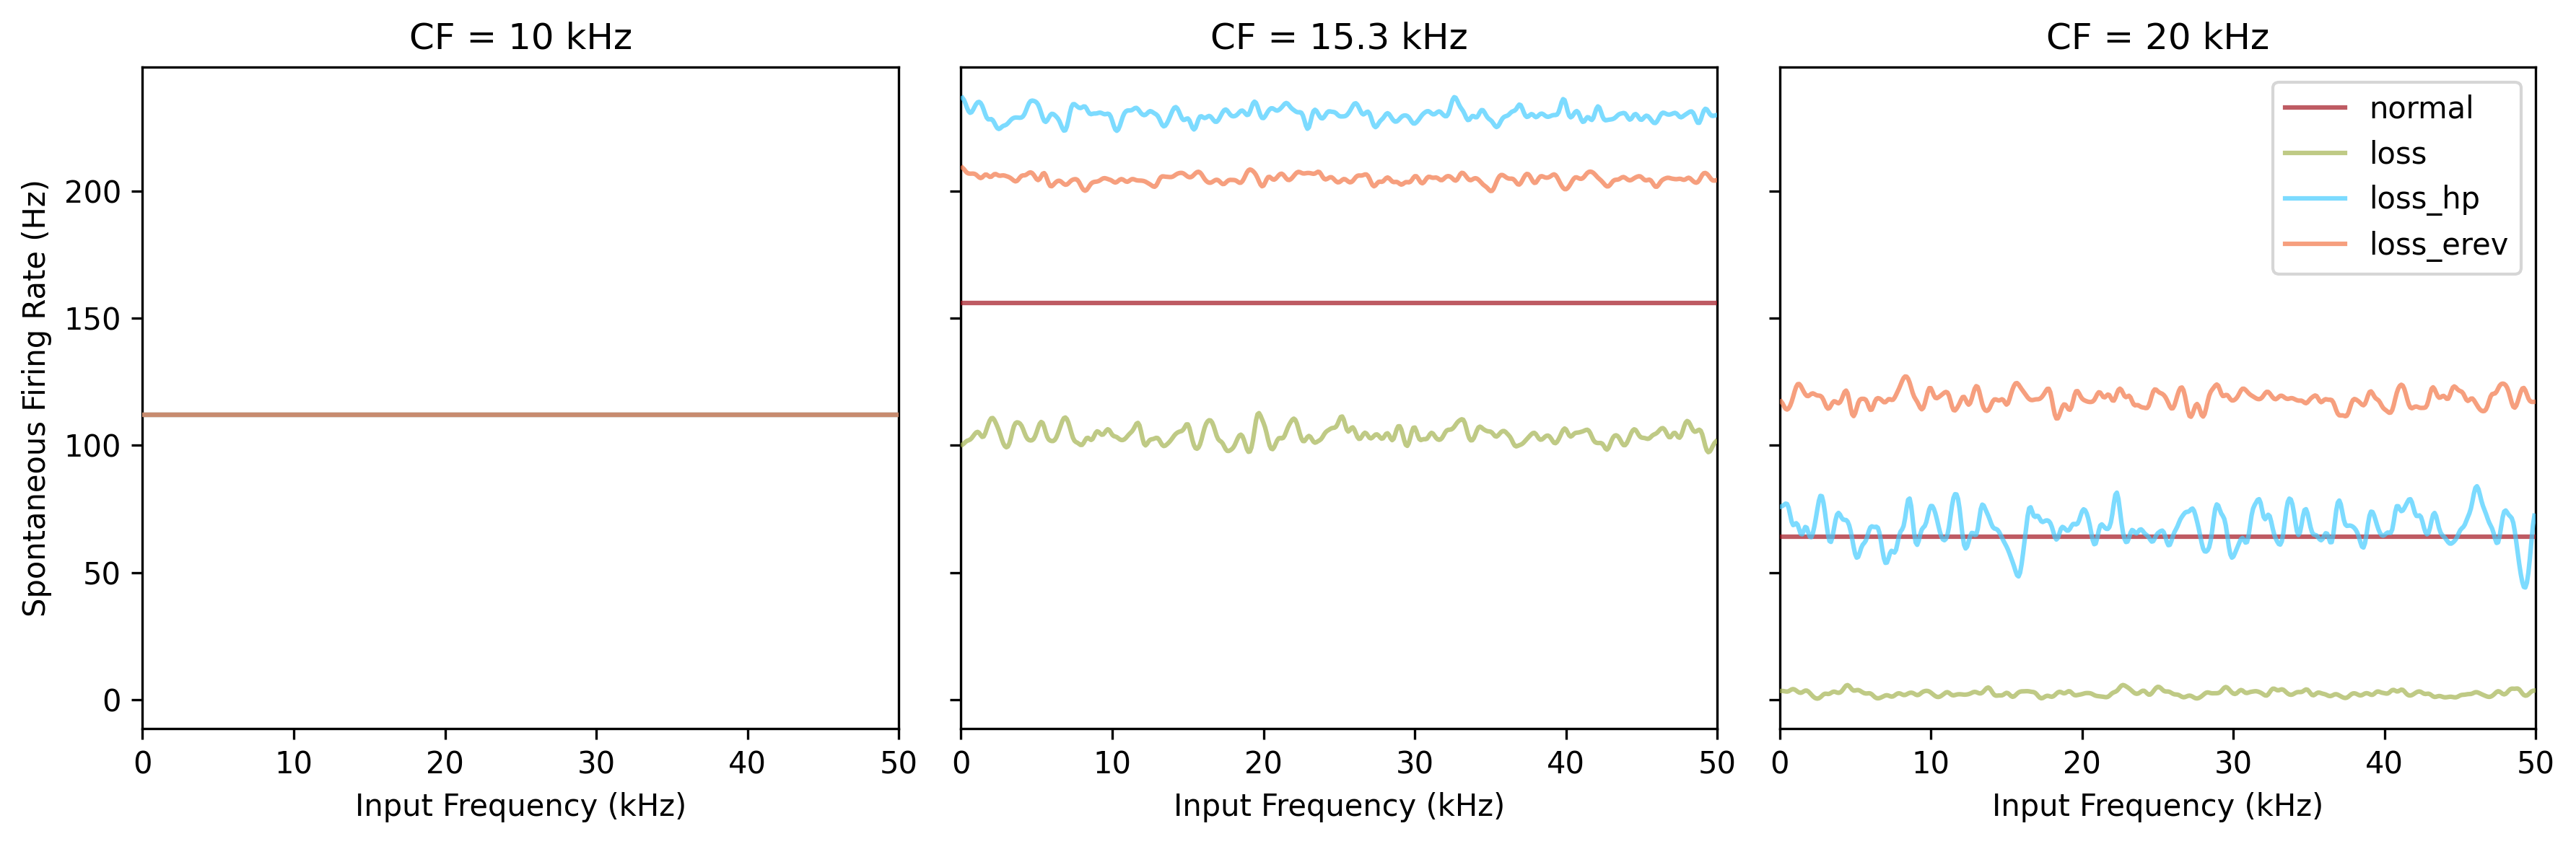

In [200]:
octave = 1
octave_xlim = False

freq_xlim = False
smooth = True

peak_freqs = []
peak_rates = []
fwhhs = []

spont_rate = np.average(pyr_tc_df.spont_rates[0])

fig, axs = plt.subplots(1, len(cfs), figsize=(4*len(cfs), 4), sharey=True, sharex=False)
axs = axs.ravel()

for cf_i, cf in enumerate(cfs):

    cf_df = pyr_tc_df[pyr_tc_df.characteristic_freq == cf]

    for row_i, row in cf_df.iterrows():

        tuning_curve = row.spont_rates #- np.min(row.tuning_curve)  #- row.spont_rates[0]
        if smooth:
            # tuning_curve = savgol_filter(tuning_curve, window_length=11, polyorder=3)
            tuning_curve = gaussian_filter1d(tuning_curve, sigma=2)
        
        axs[cf_i].plot(input_freqs_full - cf*0e3, tuning_curve, label=row.hearing, color=hearing_colors[row.hearing], alpha=0.7, zorder=12)
        # peak_idx = np.argmax(tuning_curve)
        # peak_rate = tuning_curve[peak_idx]
        # peak_freq = input_freqs_full[peak_idx]

        # axs[cf_i].hlines(half_height, left-cf*0e3, right-cf*0e3, color=hearing_colors[row.hearing], linestyle='--', lw=2, alpha=0.8, zorder=1)

        # axs[cf_i].axvline(peak_freq - cf*0e3, color=hearing_colors[row.hearing], alpha=0.7, zorder=1)

        # peak_freqs.append(peak_freq)
        # peak_rates.append(peak_rate)
        # fwhhs.append(right-left)

        # print(f'{cf} - {row.hearing} - peak at {input_freqs[peak_idx]} kHz')
        # print(f'{cf} - {row.hearing} - FWHH = {np.round((right - left)*1e-3,2)} kHz')

    axs[cf_i].set_title(f'CF = {cf} kHz')
    if octave_xlim:
        xlims = [cf*1e3 * 2**-octave, cf*1e3 * 2**octave]
        print(cf, xlims)
        axs[cf_i].set_xlim(xlims)

axs[0].set_ylabel('Spontaneous Firing Rate (Hz)')
# axs[0].set_xlim([-20000, 20000])

for ax in axs:
    # ax.set_xlabel('Distance from BF (kHz)')
    if octave_xlim:
        ax.set_xlabel('Distance from BF (octaves)')
    elif freq_xlim:
        f_dist = 10
        ax.set_xlabel('Input Frequency from BF (kHz)')
        ax.set_xlim([-f_dist*1e3, f_dist*1e3])
        ax.set_xticks([-f_dist*1e3, 0, f_dist*1e3])
        ax.set_xticklabels([-f_dist, 0, f_dist])
    else:
        ax.set_xlabel('Input Frequency (kHz)')
        ax.set_xticks([0, 10000, 20000, 30000, 40000, 50000])
        ax.set_xticklabels([0, 10, 20, 30, 40, 50])
        ax.set_xlim([0,50000])

axs[-1].legend(loc='upper right')
fig.set_dpi(300)
fig.tight_layout()

# fig.savefig('PCA-tuning_curves.png', bbox_inches='tight', dpi=300)
# fig.savefig('PCA-tuning_curves.pdf', bbox_inches='tight', dpi=300)
